# 01. Data cleaning

Raw World Stock Prices data to a clean one-row-per-(Date, Ticker) table, on a consistent
split basis. Each step below shows the problem, applies the fix, and reports how many rows it
changed. The same functions live in `formative_1/stock_data.py`, so training and the
prediction script use identical cleaning.

Next: `02_features.ipynb` builds the model inputs from the table saved here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from IPython.display import Markdown, display

from formative_1 import stock_data as sd

OUT = Path("../data/processed")
OUT.mkdir(parents=True, exist_ok=True)

## Raw data

In [2]:
raw = sd.read_raw()
raw.head()

Date,Open,High,Low,Close,Volume,Brand_Name,Ticker,Industry_Tag,Country,Dividends,Stock Splits,Capital Gains,day
str,f64,f64,f64,f64,f64,str,str,str,str,f64,f64,str,date
"""2025-07-03 00:00:00-04:00""",6.63,6.74,6.615,6.64,4.209664e6,"""peloton""","""PTON""","""fitness""","""usa""",0.0,0.0,null,2025-07-03
"""2025-07-03 00:00:00-04:00""",106.75,108.370003,106.330101,107.339996,560190.0,"""crocs""","""CROX""","""footwear""","""usa""",0.0,0.0,null,2025-07-03
"""2025-07-03 00:00:00-04:00""",122.629997,123.050003,121.550003,121.93,36600.0,"""adidas""","""ADDYY""","""apparel""","""germany""",0.0,0.0,null,2025-07-03
"""2025-07-03 00:00:00-04:00""",221.705002,224.009995,221.360001,223.410004,2.9295154e7,"""amazon""","""AMZN""","""e-commerce""","""usa""",0.0,0.0,null,2025-07-03
"""2025-07-03 00:00:00-04:00""",212.145004,214.649994,211.810104,213.550003,3.4697317e7,"""apple""","""AAPL""","""technology""","""usa""",0.0,0.0,null,2025-07-03


In [3]:
display(Markdown(f"""
**{raw.height:,} rows**, {raw['Ticker'].n_unique()} tickers, from {raw['day'].min()} to
{raw['day'].max()}. One row is one ticker on one trading day (OHLCV plus dividends and splits).
"""))
raw.null_count()


**310,122 rows**, 62 tickers, from 2000-01-03 to
2025-07-03. One row is one ticker on one trading day (OHLCV plus dividends and splits).


Date,Open,High,Low,Close,Volume,Brand_Name,Ticker,Industry_Tag,Country,Dividends,Stock Splits,Capital Gains,day
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,310120,0


Only `Capital Gains` has nulls. It is not used by the model, so it is left alone.

## Step 1. Duplicate (Date, Ticker) rows

The "daily updating" source sometimes records a day twice. The copies differ slightly in price
and volume, so they are not exact duplicates. We keep the last copy of each pair.

In [4]:
dupes = raw.filter(pl.struct("Date", "Ticker").is_duplicated()).sort("Ticker", "Date")
dupes.select("Ticker", "Date", "Open", "Close", "Volume").head(6)

Ticker,Date,Open,Close,Volume
str,str,f64,f64,f64
"""AAPL""","""2023-09-08 00:00:00-04:00""",178.350006,178.179993,6.5602066e7
"""AAPL""","""2023-09-08 00:00:00-04:00""",178.350006,178.179993,6.55513e7
"""AAPL""","""2023-09-13 00:00:00-04:00""",176.509995,174.210007,8.41658e7
"""AAPL""","""2023-09-13 00:00:00-04:00""",176.509995,174.210007,8.42679e7
"""AAPL""","""2023-09-15 00:00:00-04:00""",176.479996,175.009995,1.092051e8
"""AAPL""","""2023-09-15 00:00:00-04:00""",176.479996,175.009995,1.09259461e8


In [5]:
deduped = sd.dedupe(raw)
removed_dupes = raw.height - deduped.height
display(Markdown(f"{dupes.height:,} rows share a (Date, Ticker) pair. Keeping the last copy drops **{removed_dupes:,}** rows."))
assert deduped.select("Date", "Ticker").is_duplicated().sum() == 0

7,354 rows share a (Date, Ticker) pair. Keeping the last copy drops **3,677** rows.

## Step 2. Zero-volume rows

A day with no trades has a stale, carried-forward quote. Imputing it would create fake zero
returns, so these rows are dropped.

In [6]:
zero_volume = (
    deduped.filter(pl.col("Volume") == 0)
    .group_by("Ticker").agg(rows=pl.len()).sort("rows", descending=True)
)
zero_volume.head(8)

Ticker,rows
str,u32
"""PMMAF""",1737
"""UBSFY""",585
"""BAMXF""",578
"""LVMUY""",153
"""NTDOY""",16
"""ADDYY""",4
"""SHOP""",1
"""TWTR""",1


In [7]:
traded = sd.drop_untraded(deduped)
removed_untraded = deduped.height - traded.height
display(Markdown(f"{zero_volume['rows'].sum():,} zero-volume rows, concentrated in thinly traded foreign tickers. After dropping them **{traded.height:,}** rows remain."))
deduped.filter(pl.col('Ticker') == 'TWTR')

3,076 zero-volume rows, concentrated in thinly traded foreign tickers. After dropping them **303,369** rows remain.

Date,Open,High,Low,Close,Volume,Brand_Name,Ticker,Industry_Tag,Country,Dividends,Stock Splits,Capital Gains,day
str,f64,f64,f64,f64,f64,str,str,str,str,f64,f64,str,date
"""2025-06-11 00:00:00-04:00""",0.0,0.0,0.0,53.700001,0.0,"""twitter""","""TWTR""","""social media""","""usa""",0.0,0.0,null,2025-06-11


## Step 3. Stock-split seams

If a ticker's history is on a different split basis from its recent data, the price appears to
crash by a whole-number factor in a single day. That is an artefact, not a return, and it would
dominate the log-return features. We look for one-day drops above 5x.

In [8]:
seams = sd.find_seams(traded)
seams

Ticker,seam_day,factor
str,date,f64
"""CMG""",2024-06-24,50.0
"""NVDA""",2023-09-21,10.0


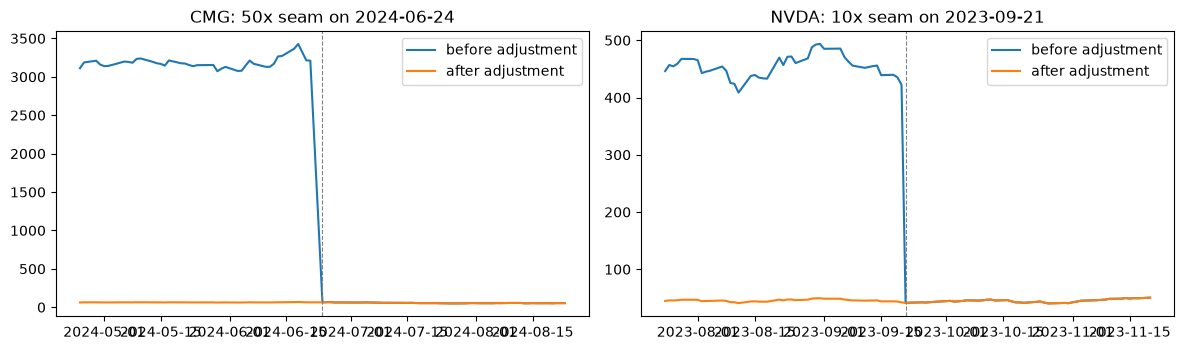

In [9]:
adjusted = sd.adjust_splits(traded, seams)

fig, axes = plt.subplots(1, len(seams), figsize=(6 * len(seams), 3.6), squeeze=False)
for ax, (ticker, seam_day, factor) in zip(axes[0], seams.iter_rows()):
    window = (pl.col("Ticker") == ticker) & pl.col("day").is_between(
        seam_day - pl.duration(days=60), seam_day + pl.duration(days=60)
    )
    ax.plot(traded.filter(window)["day"], traded.filter(window)["Close"], label="before adjustment")
    ax.plot(adjusted.filter(window)["day"], adjusted.filter(window)["Close"], label="after adjustment")
    ax.axvline(seam_day, c="grey", ls="--", lw=0.8)
    ax.set_title(f"{ticker}: {factor:.0f}x seam on {seam_day}")
    ax.legend()
fig.tight_layout()
plt.show()

### Check: reverse splits

The seam rule only catches forward splits (price falls). A reverse split would show up as a
price *jump* by a whole-number factor, which the rule would miss. We check for it.

In [10]:
jumps = (
    traded.with_columns(ratio=pl.col("Close") / pl.col("Close").shift(1).over("Ticker"))
    .filter(pl.col("ratio") > 5)
    .select("Ticker", "day", "ratio", "Close")
    .sort("ratio", descending=True)
)
display(Markdown(f"One-day price jumps above 5x: **{jumps.height}**."))
jumps.head(10)

One-day price jumps above 5x: **0**.

Ticker,day,ratio,Close
str,date,f64,f64


## Result

The largest one-day moves that remain should be real events (earnings shocks and similar), not data
errors.

In [11]:
cleaned = sd.clean(raw)
assert cleaned.equals(adjusted)  # the step-by-step result matches the module's clean()

biggest = (
    cleaned.with_columns(log_ret=pl.col("Close").log().diff().over("Ticker"))
    .drop_nulls("log_ret")
    .sort(pl.col("log_ret").abs(), descending=True)
    .select("Ticker", "day", "Close", "log_ret")
    .head(8)
)
biggest

Ticker,day,Close,log_ret
str,date,f64,f64
"""AAPL""",2000-09-29,0.390294,-0.731248
"""FL""",2025-05-15,23.9,0.618979
"""CROX""",2008-11-13,1.05,-0.593064
"""CROX""",2008-07-25,4.95,-0.592266
"""CROX""",2008-04-15,10.11,-0.565112
"""NFLX""",2004-10-15,1.471429,-0.526049
"""CROX""",2011-10-18,16.15,-0.500494
"""CROX""",2007-11-01,47.740002,-0.44838


In [12]:
summary = pl.DataFrame(
    {
        "step": ["raw", "dedupe (Date, Ticker)", "drop zero volume", "split adjustment (no rows removed)"],
        "rows": [raw.height, deduped.height, traded.height, cleaned.height],
        "removed": [0, removed_dupes, removed_untraded, 0],
    }
)
summary

step,rows,removed
str,i64,i64
"""raw""",310122,0
"""dedupe (Date, Ticker)""",306445,3677
"""drop zero volume""",303369,3076
"""split adjustment (no rows remo…",303369,0


In [13]:
cleaned.write_parquet(OUT / "clean.parquet")
print(f"saved {cleaned.height:,} rows, {cleaned['Ticker'].n_unique()} tickers to {OUT / 'clean.parquet'}")

saved 303,369 rows, 61 tickers to ../data/processed/clean.parquet
